# 02 · Exploratory Data Analysis

Traffic, channels, devices, landing pages, events and revenue. Charts are produced by `python/analysis.py` and saved to `reports/figures/`.

> **Synthetic data disclosure.** All data in this project is generated by `python/generate_sample_data.py` (seed 42). It is realistic in structure but does **not** describe any real company. Findings demonstrate the analytical method, not real performance.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "python"))
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
FIG = ROOT / "reports" / "figures"; MET = ROOT / "reports" / "metrics"
def show(name, width=900): display(Image(filename=str(FIG / name), width=width))
def pct(df, cols): return df.style.format({c: "{:.2%}" for c in cols})
import analysis as an, metrics as m
kpis, recon, T = an.run_all()
pd.Series(kpis)

total_sessions              35822.000000
total_visitors              25729.000000
engaged_sessions            25853.000000
engagement_rate                 0.721707
purchasing_sessions           913.000000
purchase_conversion_rate        0.025487
total_transactions            913.000000
total_revenue               64206.740000
net_revenue                 62536.950000
average_order_value            70.325016
revenue_per_session             1.792383
dtype: float64

**Headline:** 35,822 sessions from 25,729 visitors; 913 purchasing sessions (2.55% conversion), $64.2k gross revenue, AOV ≈ $70, revenue per session ≈ $1.79. Engagement rate is 72% (engaged = 2+ page views, a product view, a purchase, or a long first page).

## 1. Sessions over time

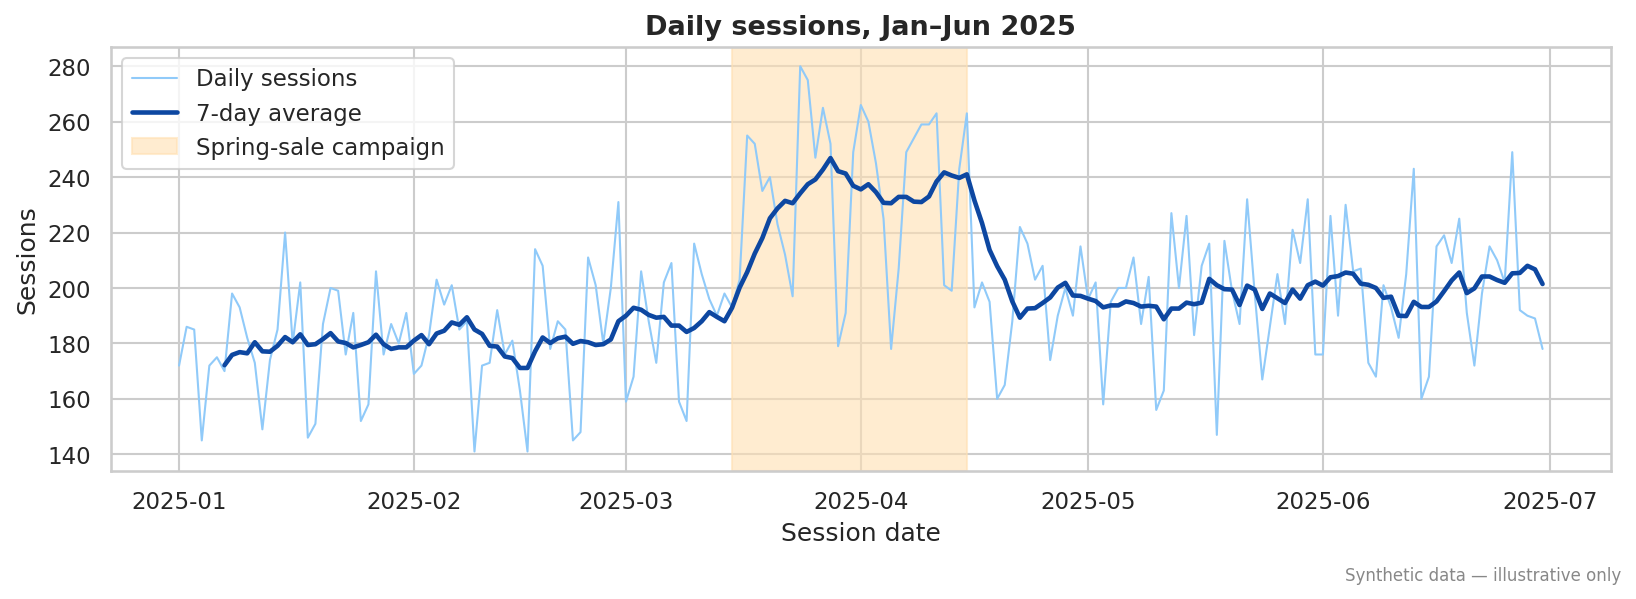

,month,sessions,purchasing_sessions,revenue,conversion_rate,revenue_per_session,sessions_growth_pct,revenue_growth_pct
0,2025-01,5561,152,10452.07,0.027333,1.879531,NaN,NaN
1,2025-02,5123,125,9121.41,0.024400,1.780482,-0.078763,-0.127311
2,2025-03,6569,149,9857.12,0.022682,1.500551,0.282256,0.080657
3,2025-04,6492,162,11582.08,0.024954,1.784054,-0.011722,0.174996
4,2025-05,6095,159,10500.63,0.026087,1.722827,-0.061152,-0.093373
5,2025-06,5982,166,12693.43,0.027750,2.121937,-0.018540,0.208826


In [2]:
show('01_daily_sessions.png')
T['monthly_trend'][['month','sessions','purchasing_sessions','revenue','conversion_rate','revenue_per_session','sessions_growth_pct','revenue_growth_pct']]

**Reading the chart.** Traffic is stable at ~180–200 sessions/day with a clear weekly cycle (weekend dips). Volume jumps during the spring-sale window (15 Mar – 15 Apr). March sessions rose 28% vs February, but revenue rose only 8%, and March has the lowest conversion rate (2.27%) and revenue per session ($1.50). **Worth investigating:** the extra traffic was lower-intent; see the channel and campaign sections.

## 2. Traffic sources and channels

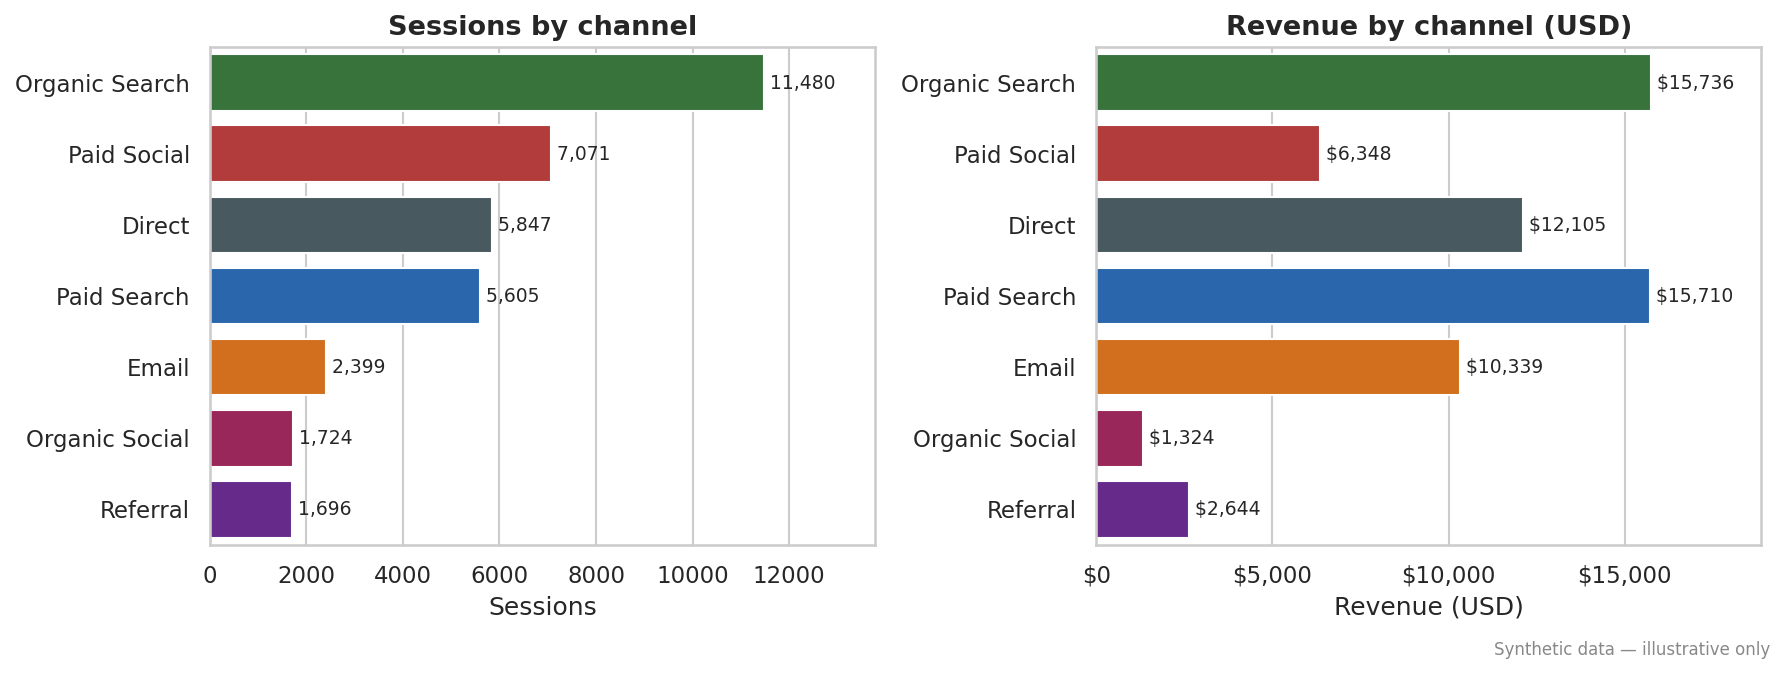

,channel_group,sessions,share_of_sessions,purchasing_sessions,conversion_rate,revenue,share_of_revenue,revenue_per_session,average_order_value
0,Organic Search,11480,32.0%,232,2.02%,"$15,736",24.5%,$1.37,$67.83
1,Paid Social,7071,19.7%,84,1.19%,"$6,348",9.9%,$0.90,$75.57
2,Direct,5847,16.3%,173,2.96%,"$12,105",18.9%,$2.07,$69.97
3,Paid Search,5605,15.6%,223,3.98%,"$15,710",24.5%,$2.80,$70.45
4,Email,2399,6.7%,145,6.04%,"$10,339",16.1%,$4.31,$71.31
5,Organic Social,1724,4.8%,14,0.81%,"$1,324",2.1%,$0.77,$94.56
6,Referral,1696,4.7%,42,2.48%,"$2,644",4.1%,$1.56,$62.96


In [3]:
show('02_sessions_and_revenue_by_channel.png')
cols=['channel_group','sessions','share_of_sessions','purchasing_sessions','conversion_rate','revenue','share_of_revenue','revenue_per_session','average_order_value']
pct(T['channel_performance'][cols], ['share_of_sessions','conversion_rate','share_of_revenue']).format({'revenue':'${:,.0f}','revenue_per_session':'${:.2f}','average_order_value':'${:.2f}','share_of_sessions':'{:.1%}','conversion_rate':'{:.2%}','share_of_revenue':'{:.1%}'})

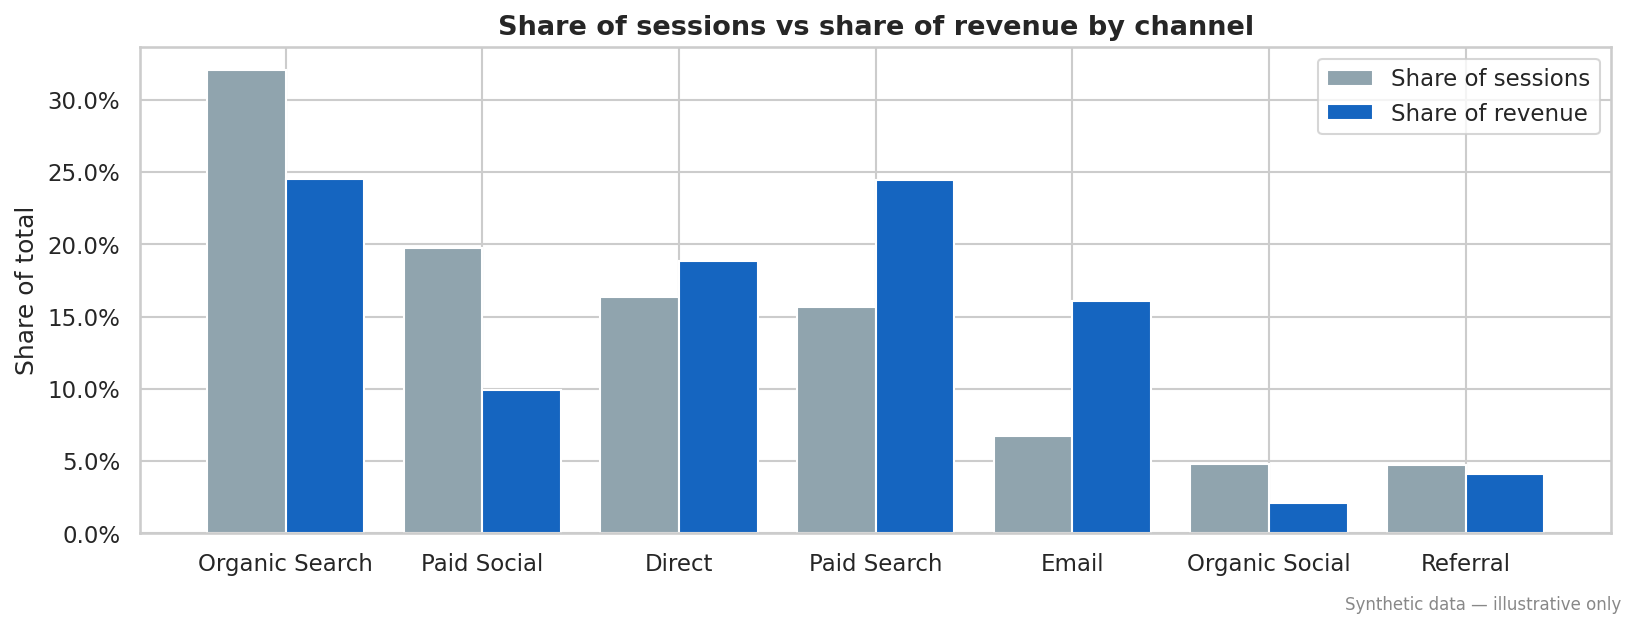

In [4]:
show('03_session_vs_revenue_share.png')

**Reading the charts.** Organic Search brings the most sessions (32%) and the most purchasing sessions. Paid Search earns the same revenue as Organic Search from half the sessions. Paid Social is the second-largest traffic source (19.7% of sessions) but returns only 9.9% of revenue. Email is the mirror image: 6.7% of sessions, 16.1% of revenue.

## 3. Marketing-medium / source performance

In [5]:
sm = T['source_medium_performance'][['channel_group','source_medium','sessions','purchasing_sessions','conversion_rate','revenue','revenue_per_session']]
sm.style.format({'conversion_rate':'{:.2%}','revenue':'${:,.0f}','revenue_per_session':'${:.2f}'})

,channel_group,source_medium,sessions,purchasing_sessions,conversion_rate,revenue,revenue_per_session
0,Organic Search,google / organic,10434,211,2.02%,"$14,284",$1.37
1,Direct,(direct) / (none),5847,173,2.96%,"$12,105",$2.07
2,Paid Search,google / cpc,5605,223,3.98%,"$15,710",$2.80
3,Paid Social,facebook / paid_social,4150,50,1.20%,"$3,645",$0.88
4,Paid Social,instagram / paid_social,2921,34,1.16%,"$2,703",$0.93
5,Email,newsletter / email,2399,145,6.04%,"$10,339",$4.31
6,Organic Search,bing / organic,1046,21,2.01%,"$1,453",$1.39
7,Referral,partnerblog.com / referral,1017,31,3.05%,"$1,976",$1.94
8,Organic Social,instagram / social,1001,8,0.80%,$697,$0.70
9,Organic Social,tiktok / social,723,6,0.83%,$627,$0.87


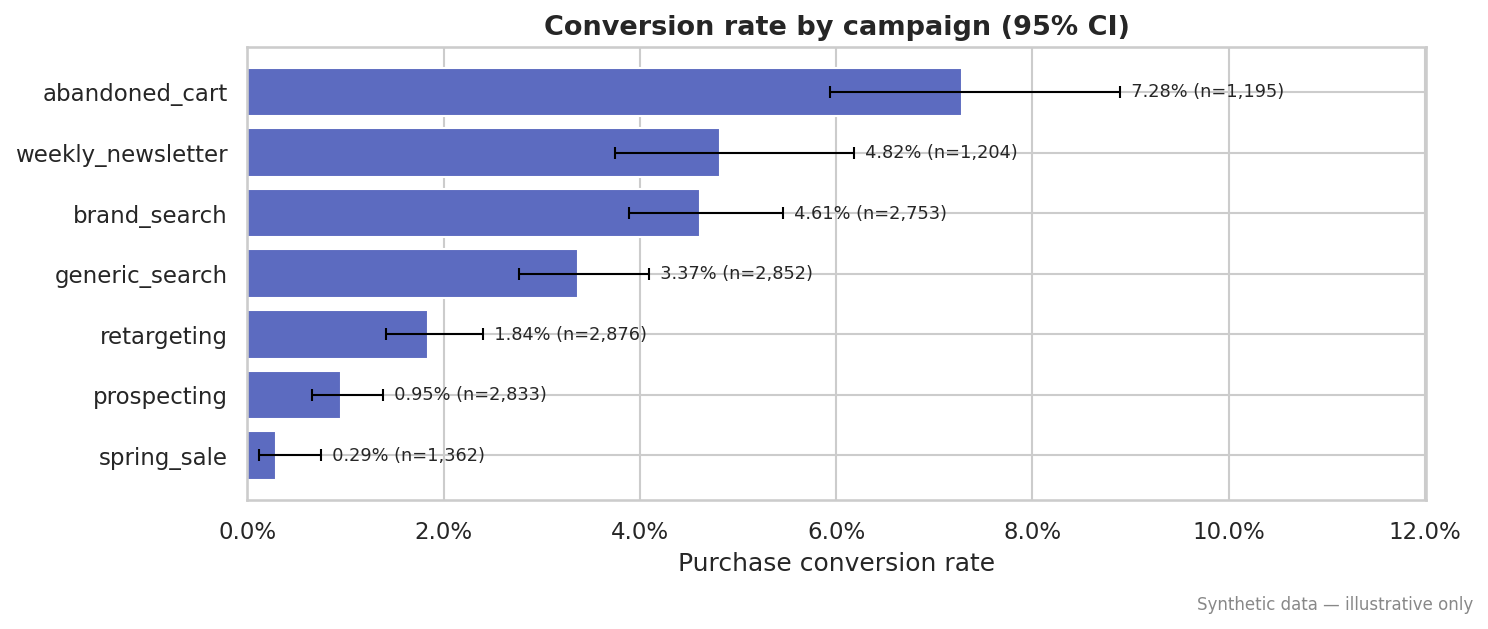

In [6]:
show('12_campaign_conversion.png')

Within paid media the campaign matters as much as the channel: `brand_search` (4.6%) converts far above `generic_search` (3.4%), and `abandoned_cart` email is the best converter in the dataset (7.3%). The `spring_sale` paid-social campaign converts at 0.29%; its confidence interval sits well below every other campaign's. *These comparisons are observational: campaigns target different audiences, so they rank where to look, not what caused the difference.*

## 4. Device distribution and performance

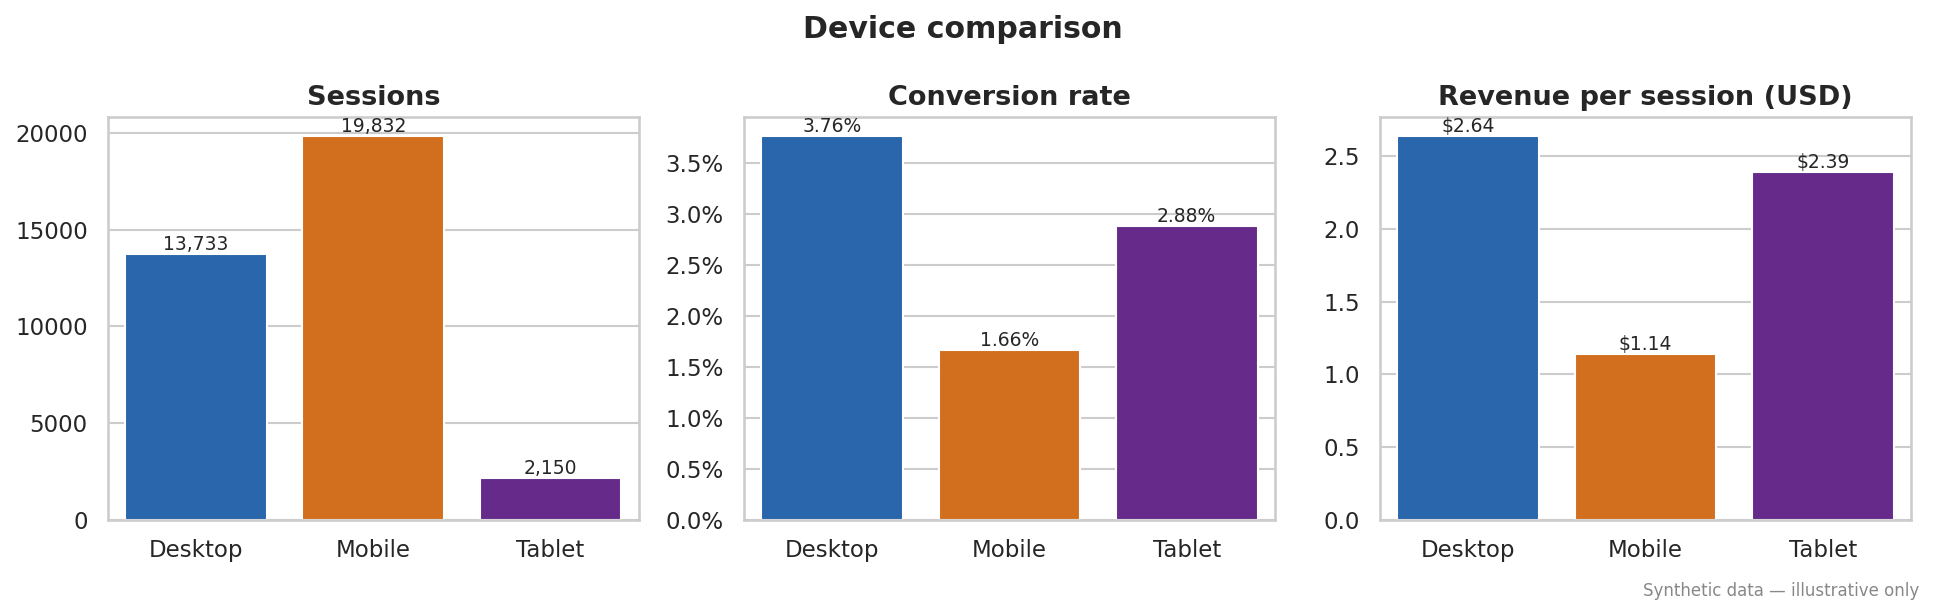

,device_label,sessions,share_of_sessions,conversion_rate,revenue_per_session,average_order_value,share_of_revenue
0,Mobile,19832,55.4%,1.66%,$1.14,$68.39,35.1%
1,Desktop,13733,38.3%,3.76%,$2.64,$70.16,56.4%
2,Tablet,2150,6.0%,2.88%,$2.39,$83.01,8.0%
3,Unknown,107,0.3%,4.67%,$2.70,$57.67,0.4%


In [7]:
show('05_device_comparison.png', 1000)
T['device_performance'][['device_label','sessions','share_of_sessions','conversion_rate','revenue_per_session','average_order_value','share_of_revenue']].style.format({'share_of_sessions':'{:.1%}','conversion_rate':'{:.2%}','revenue_per_session':'${:.2f}','average_order_value':'${:.2f}','share_of_revenue':'{:.1%}'})

Mobile is 55% of sessions but 35% of revenue; its conversion rate (1.66%) is less than half of desktop's (3.76%). Mobile is over-represented in Paid Social, so part of the gap could be channel mix. The next chart checks that by comparing devices **within** each channel.

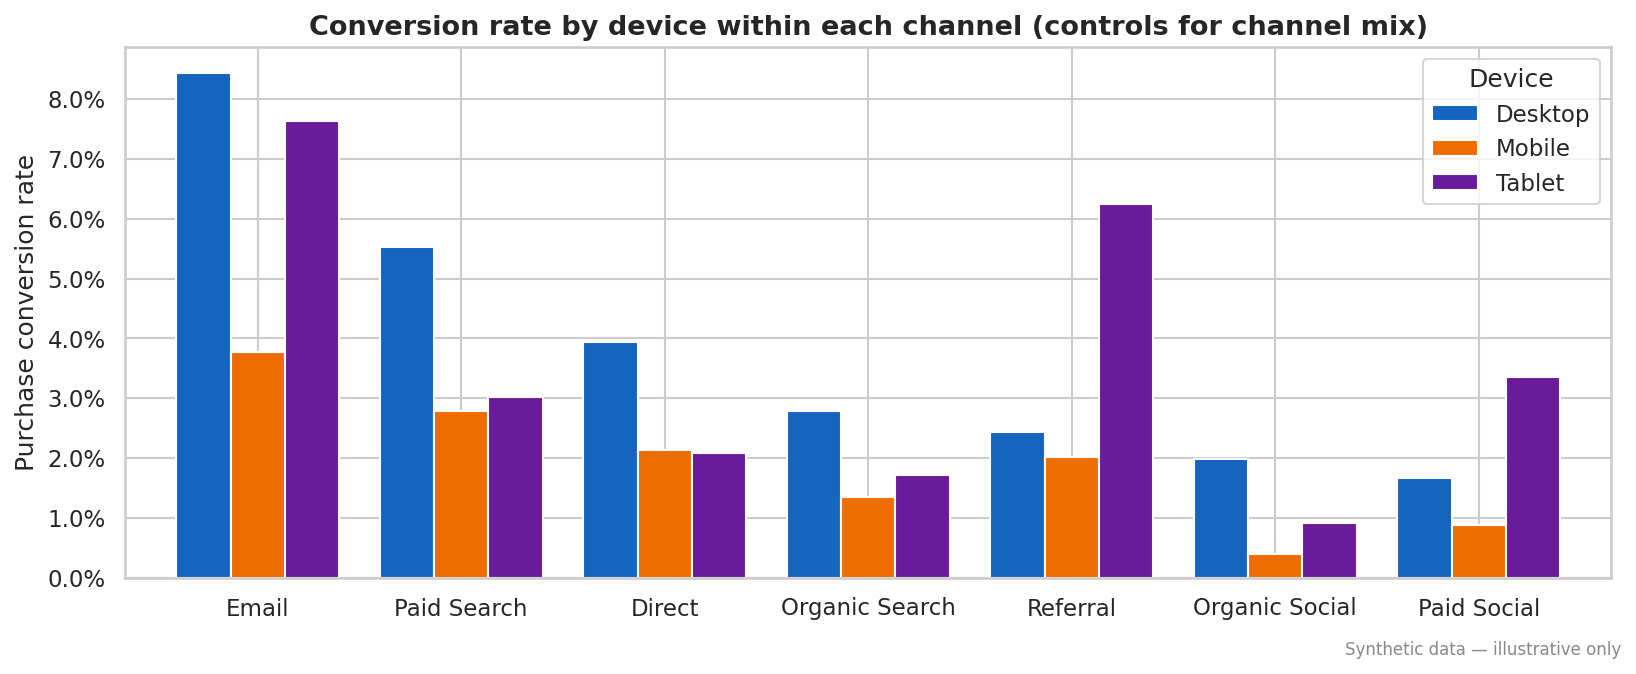

device_label,Desktop,Mobile,Tablet
channel_group,,,
Direct,3.94%,2.14%,2.08%
Email,8.45%,3.78%,7.64%
Organic Search,2.78%,1.35%,1.72%
Organic Social,1.98%,0.40%,0.91%
Paid Search,5.53%,2.79%,3.01%
Paid Social,1.66%,0.89%,3.35%
Referral,2.43%,2.02%,6.25%


In [8]:
show('13_device_within_channel.png')
T['device_within_channel'].pivot(index='channel_group', columns='device_label', values='conversion_rate').style.format('{:.2%}')

Mobile converts below desktop in **every** channel, so the gap is not just a mix effect. (Tablet's high values in Referral and Paid Social rest on 112 and 418 sessions; they are noise-prone.) Notebook 03 locates *where* in the funnel mobile loses users. The 107 `unknown`-device sessions are excluded from device comparisons.

## 5. Landing pages

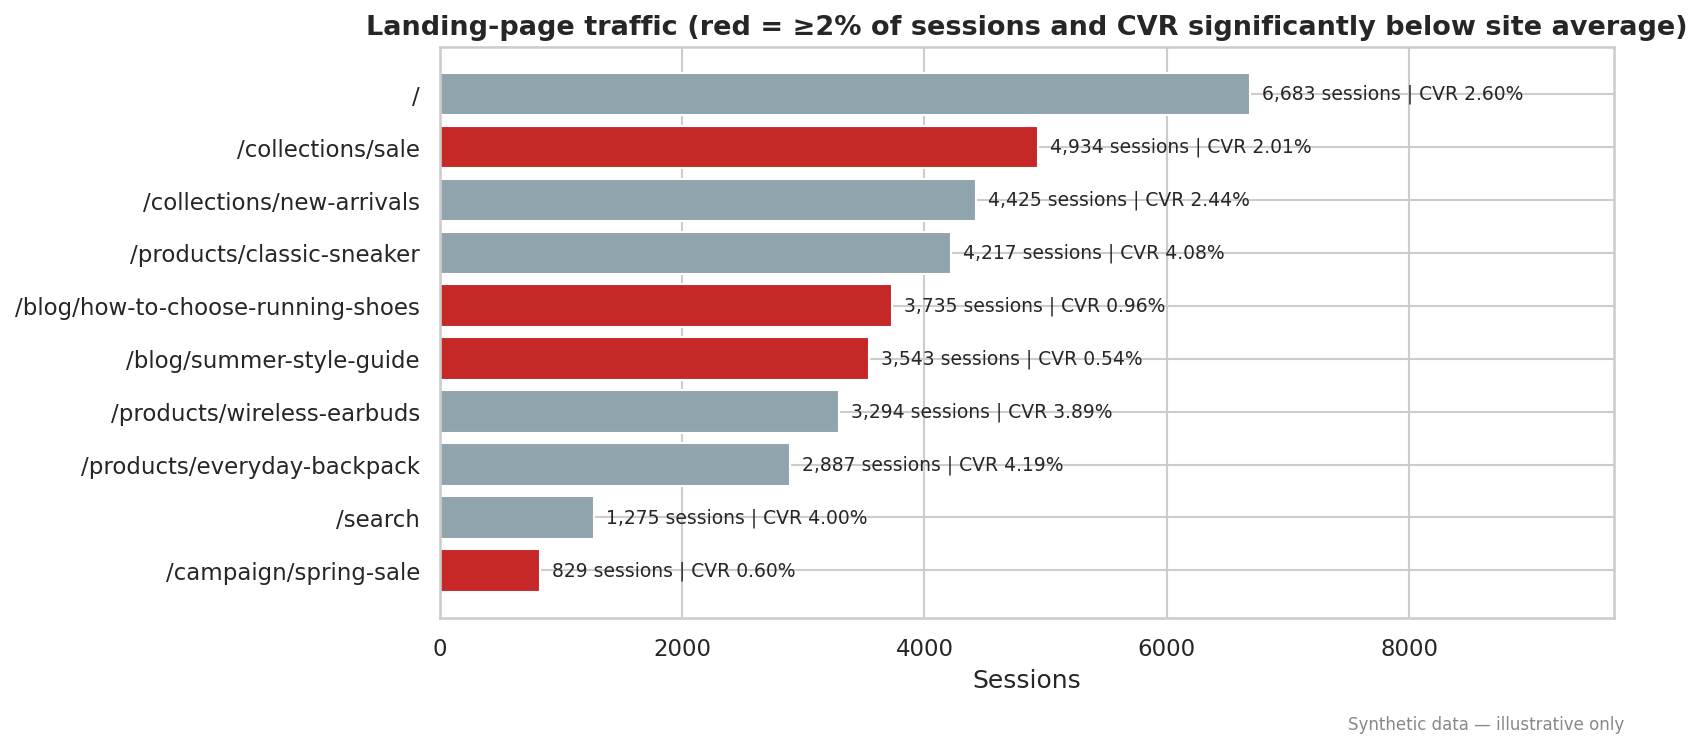

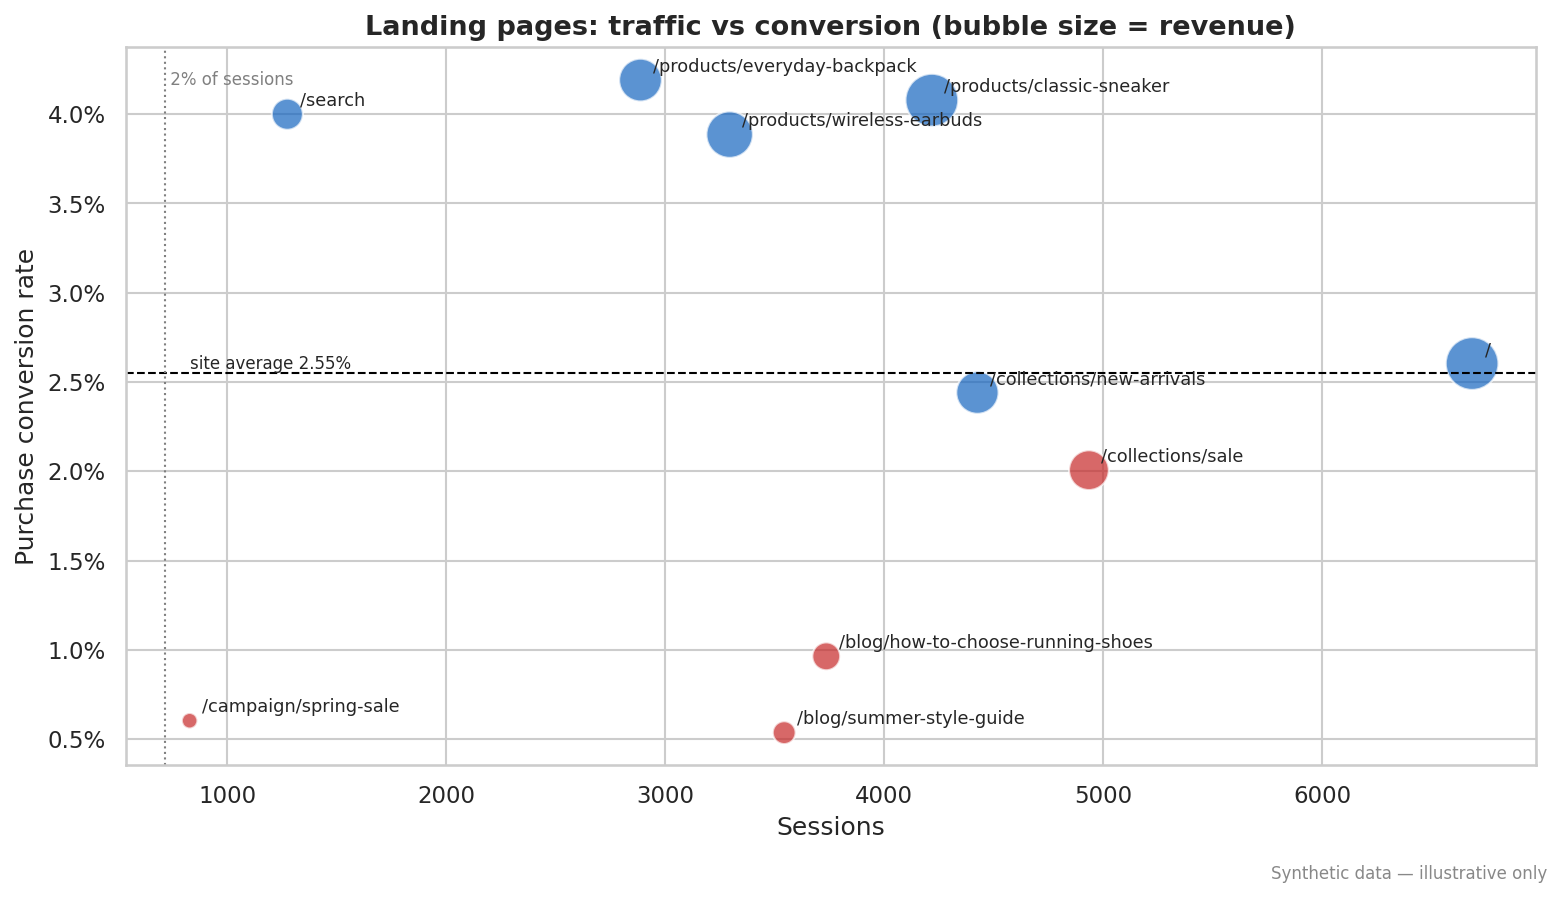

,landing_page,page_type,sessions,share_of_sessions,engagement_rate,add_to_cart_rate,conversion_rate,cvr_ci_low,cvr_ci_high,revenue,investigate
0,/,Home,6683,18.7%,68.5%,10.7%,2.60%,2.25%,3.01%,"$12,225",False
1,/collections/sale,Collection,4934,13.8%,74.1%,8.6%,2.01%,1.65%,2.44%,"$6,606",True
2,/collections/new-arrivals,Collection,4425,12.4%,74.3%,10.7%,2.44%,2.03%,2.94%,"$7,583",False
3,/products/classic-sneaker,Product,4217,11.8%,86.3%,18.9%,4.08%,3.52%,4.72%,"$12,244",False
4,/blog/how-to-choose-running-shoes,Blog,3735,10.4%,52.0%,2.8%,0.96%,0.70%,1.33%,"$2,821",True
5,/blog/summer-style-guide,Blog,3543,9.9%,50.2%,2.4%,0.54%,0.34%,0.84%,"$1,628",True
6,/products/wireless-earbuds,Product,3294,9.2%,86.8%,17.2%,3.89%,3.28%,4.60%,"$9,325",False
7,/products/everyday-backpack,Product,2887,8.1%,86.1%,16.4%,4.19%,3.52%,4.99%,"$7,739",False
8,/search,Search,1275,3.6%,77.6%,15.5%,4.00%,3.06%,5.22%,"$3,717",False
9,/campaign/spring-sale,Campaign,829,2.3%,76.4%,3.4%,0.60%,0.26%,1.40%,$320,True


In [9]:
show('06_landing_page_traffic.png')
show('07_landing_page_quadrant.png')
lp = T['landing_page_performance'][['landing_page','page_type','sessions','share_of_sessions','engagement_rate','add_to_cart_rate','conversion_rate','cvr_ci_low','cvr_ci_high','revenue','investigate']]
lp.style.format({'share_of_sessions':'{:.1%}','engagement_rate':'{:.1%}','add_to_cart_rate':'{:.1%}','conversion_rate':'{:.2%}','cvr_ci_low':'{:.2%}','cvr_ci_high':'{:.2%}','revenue':'${:,.0f}'})

**Flag rule (documented, reproducible):** a page is flagged when it carries ≥ 2% of sessions **and** the upper bound of its 95% Wilson interval for conversion is below the site average (2.55%), so the shortfall is unlikely to be sampling noise.

* `/collections/sale`: 2nd-highest traffic, 2.01% CVR. A commercial page converting below average is the clearest optimisation candidate.
* `/blog/how-to-choose-running-shoes`, `/blog/summer-style-guide`: high traffic, mostly organic, low engagement (~51%) and very low add-to-cart. Blogs are top-of-funnel content, so low last-click conversion is **expected**. The question is whether they move readers toward products (internal links, assisted conversions), not whether they convert like product pages.
* `/campaign/spring-sale`: lower traffic (only live during the campaign) but 0.60% CVR despite 76% engagement. Visitors engaged, then did not add to cart. That points at offer/price/product match rather than page load or relevance of the click.
* Product detail pages convert at ~4%, well above average, and are the strongest landing destinations.

## 6. Event frequency

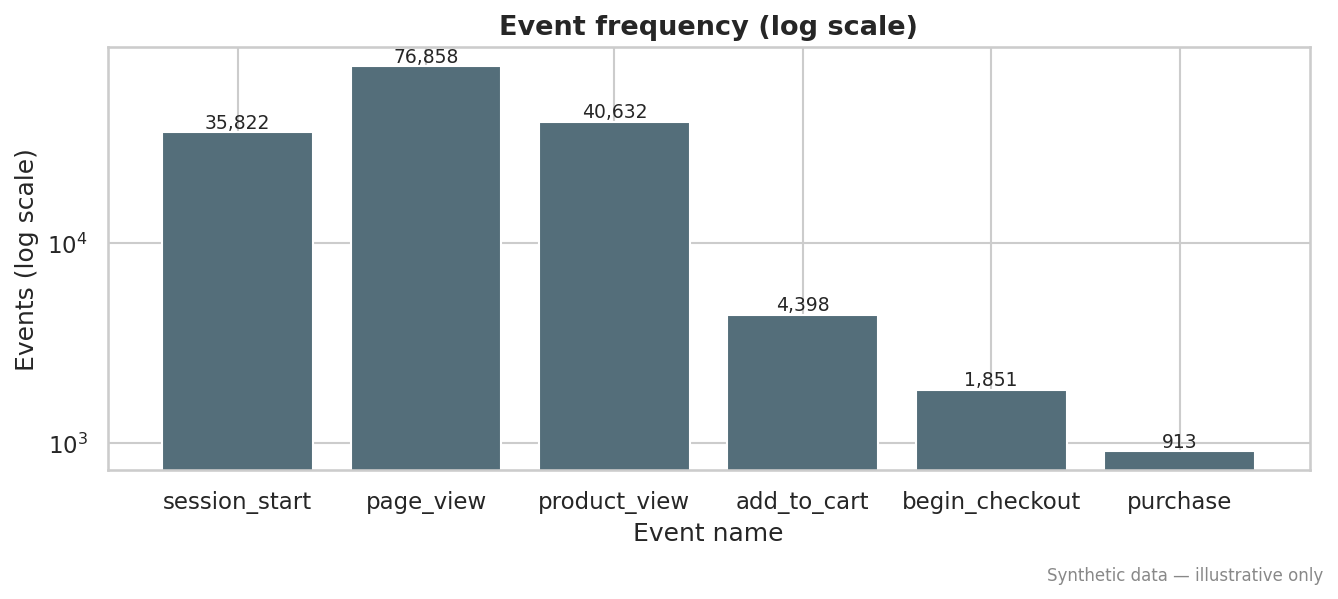

,event_name,events,sessions_with_event
0,page_view,76858,35822
1,product_view,40632,19377
2,session_start,35822,35822
3,add_to_cart,4398,3861
4,begin_checkout,1851,1851
5,purchase,913,913


In [10]:
show('08_event_frequency.png', 750)
T['event_frequency']

Event counts are **not** session counts: there are ~2.1 product views per product-viewing session. All funnel and KPI work therefore counts distinct sessions, never raw events.

## 7. Purchases and revenue over time

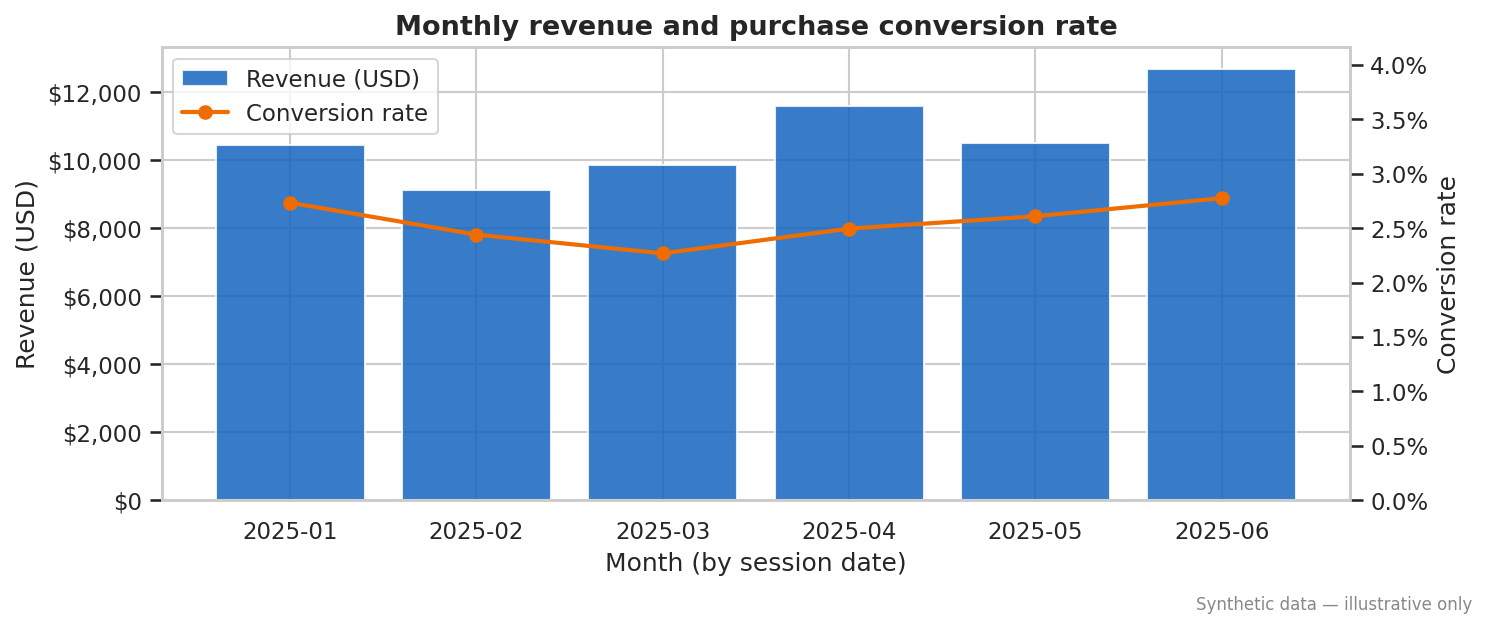

In [11]:
show('09_monthly_revenue_conversion.png', 800)

Revenue is broadly flat-to-rising (June is the strongest month). The March dip in conversion rate coincides with the campaign traffic surge, consistent with the channel findings.

## 8. Conversion by channel (with uncertainty)

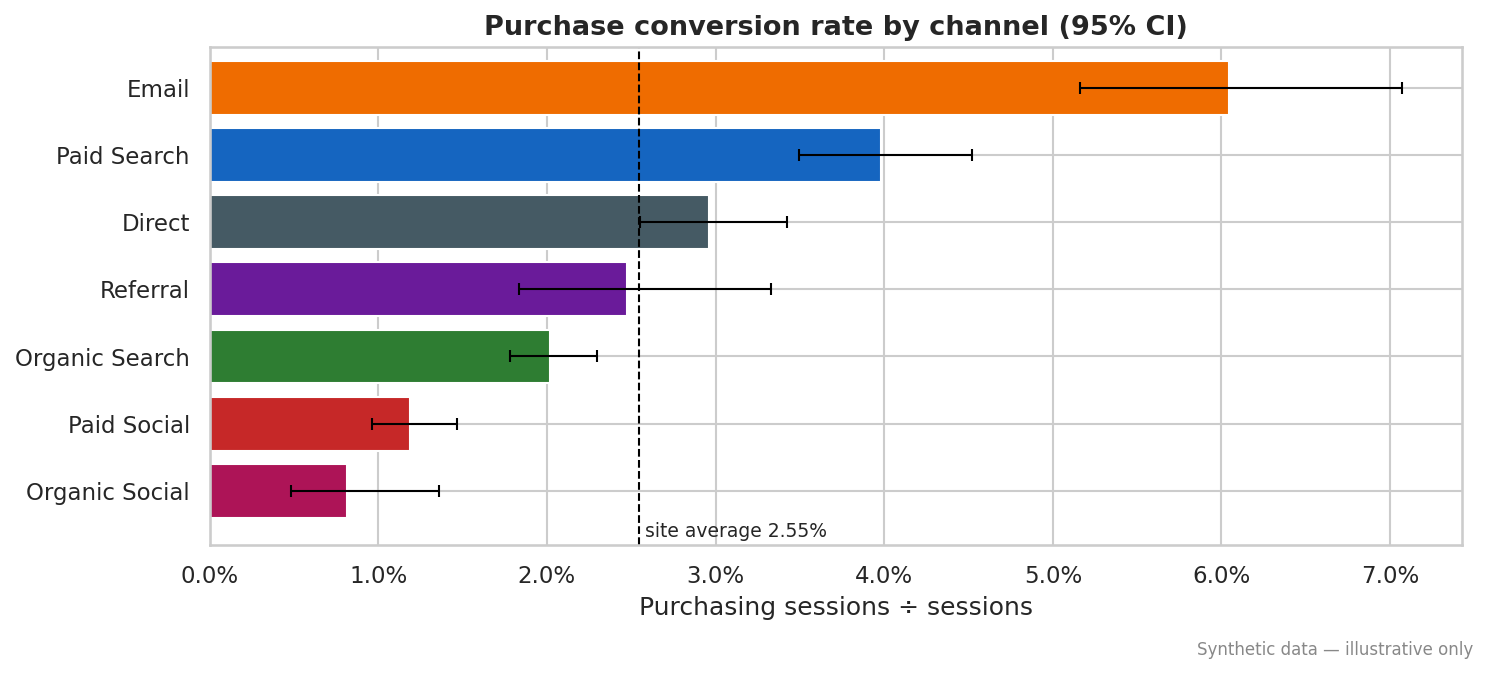

In [12]:
show('04_conversion_rate_by_channel.png', 850)

## Findings to investigate further
1. **Mobile conversion gap:** present in every channel (notebook 03 locates it in checkout).
2. **Paid Social efficiency:** high traffic share, low revenue share; the `spring_sale` and `prospecting` campaigns drive most of the shortfall.
3. **`/collections/sale` page:** high-traffic commercial page with below-average conversion.
4. **Blog content:** large organic audience; measure its role in assisted conversions before judging it.
5. **Campaign traffic quality:** March volume growth did not translate into proportional revenue.